# Ablation Study 1: CNN + Transformer Only (No BiLSTM)

This notebook removes the **BiLSTM** component and keeps CNN + Transformer.

In [1]:
import torch

# ── Kaggle P100 Compatibility Fix ──────────────────────────────────────
# The Tesla P100 (sm_60) is NOT supported by PyTorch >= 2.0.
# Kaggle's pip index also does not carry older torch builds.
# Solution: force CPU. Kaggle CPUs are fast enough for this pipeline.
device = torch.device("cuda")
print(f"Running on: {device}")
print(f"PyTorch version: {torch.__version__}")
# ───────────────────────────────────────────────────────────────────────

Running on: cuda
PyTorch version: 2.10.0+cu128


In [2]:
!pip install torch pandas numpy scikit-learn matplotlib seaborn tqdm --quiet

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix, classification_report, f1_score, accuracy_score, precision_score, recall_score
from sklearn.neighbors import NearestNeighbors
from tqdm import tqdm

np.random.seed(42)
torch.manual_seed(42)

In [5]:
CONFIG = {
    'batch_size': 512,
    'epochs': 30,
    'learning_rate': 0.001,
    'input_shape': (46, 1),
    'dataset_path': '/kaggle/input/datasets/himadri07/ciciot2023/CICIOT23',
}

ATTACK_MAPPING = {
    'DoS-TCP_Flood': 'DoS_TCP_Flood',
    'DoS-SYN_Flood': 'DoS_SYN_Flood',
    'DoS-HTTP_Flood': 'DoS_HTTP_Flood',
    'DoS-UDP_Flood': 'DoS',
    'DDoS-TCP_Flood': 'DDoS',
    'DDoS-PSHACK_Flood': 'DDoS',
    'DDoS-SYN_Flood': 'DDoS',
    'DDoS-RSTFINFlood': 'DDoS',
    'DDoS-SynonymousIP_Flood': 'DDoS',
    'DDoS-ACK_Fragmentation': 'DDoS_ACK_Fragmentation',
    'DDoS-HTTP_Flood': 'DDoS',
    'DDoS-SlowLoris': 'DDoS',
    'DDoS-UDP_Flood': 'DDoS',
    'DDoS-ICMP_Flood': 'DDoS',
    'DDoS-UDP_Fragmentation': 'DDoS',
    'DDoS-ICMP_Fragmentation': 'DDoS',
    'Mirai-greeth_flood': 'Mirai_udplain',
    'Mirai-greip_flood': 'Mirai_udplain',
    'Mirai-udpplain': 'Mirai_udplain',
    'SqlInjection': 'attack',
    'XSS': 'attack',
    'BrowserHijacking': 'attack',
    'CommandInjection': 'attack',
    'Uploading_Attack': 'attack',
    'Backdoor_Malware': 'attack',
    'MITM-ArpSpoofing': 'Spoofing',
    'DNS_Spoofing': 'Spoofing',
    'Recon-HostDiscovery': 'Recon',
    'Recon-OSScan': 'Recon',
    'Recon-PortScan': 'Recon',
    'Recon-PingSweep': 'Recon',
    'VulnerabilityScan': 'VulnerabilityScan',
    'DictionaryBruteForce': 'Recon',
    'BenignTraffic': 'Benign'
}

SEEN_CLASSES = ['Benign','VulnerabilityScan','DoS_TCP_Flood','DoS_SYN_Flood','DoS_HTTP_Flood','DDoS_ACK_Fragmentation']
UNSEEN_CLASSES = ['Mirai_udplain']
print(f"Seen classes: {SEEN_CLASSES}")
print(f"Unseen classes: {UNSEEN_CLASSES}")

Seen classes: ['Benign', 'VulnerabilityScan', 'DoS_TCP_Flood', 'DoS_SYN_Flood', 'DoS_HTTP_Flood', 'DDoS_ACK_Fragmentation']
Unseen classes: ['Mirai_udplain']


In [7]:
class IoTDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

def load_and_process(config):
    try:
        # df1 = pd.read_csv(config['dataset_path'] + "/test/test.csv")
        df = pd.read_csv(config['dataset_path'] + "/train/train.csv")
        # df = pd.concat([df1, df2], ignore_index=True)
        print(f"Duplicated values: {df.duplicated().sum()}")
        df = df.drop_duplicates()
    except FileNotFoundError:
        print("File not found.")
        return None, None, None, None

    df["category"] = df["label"].map(ATTACK_MAPPING)
    df = df[df["category"].notna()]
    for drop_cat in ["Spoofing", "Recon", "attack", "DDoS", "DoS"]:
        df = df[df["category"] != drop_cat]
    allowed = set(SEEN_CLASSES) | set(UNSEEN_CLASSES)
    df = df[df["category"].isin(allowed)].copy()

    X = df.drop(["label", "category"], axis=1)
    feature_names = X.columns.tolist()
    X = X.apply(pd.to_numeric, errors="coerce").values.astype(np.float32)
    y = df["category"].values.astype(object)
    y_raw = df["label"].values.astype(object)
    return X, y, y_raw, feature_names

X, y, y_raw, feature_names = load_and_process(CONFIG)
if X is None:
    raise RuntimeError("Dataset load failed.")

seen_indices = np.isin(y, SEEN_CLASSES)
unseen_indices = np.isin(y, UNSEEN_CLASSES)
X_seen, y_seen = X[seen_indices], y[seen_indices]
X_unseen, y_unseen = X[unseen_indices], y[unseen_indices]

le = LabelEncoder()
y_seen_enc = le.fit_transform(y_seen)
num_classes = len(le.classes_)

X_train, X_temp, y_train, y_temp = train_test_split(
    X_seen, y_seen_enc, test_size=0.30, random_state=42, stratify=y_seen_enc)
X_val, X_test_seen, y_val, y_test_seen = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train)
X_val = imputer.transform(X_val)
X_test_seen = imputer.transform(X_test_seen)
X_unseen_imp = imputer.transform(X_unseen)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test_seen = scaler.transform(X_test_seen)
X_unseen_imp = scaler.transform(X_unseen_imp)

y_test_seen_str = le.inverse_transform(y_test_seen)
X_test_final = np.concatenate([X_test_seen, X_unseen_imp], axis=0)
y_test_final_str = np.concatenate([y_test_seen_str, y_unseen], axis=0)

# Reshape for model: (N, Features, 1)
X_train_3d = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_val_3d   = X_val.reshape(X_val.shape[0], X_val.shape[1], 1)
X_test_3d  = X_test_final.reshape(X_test_final.shape[0], X_test_final.shape[1], 1)

y_test_dummy = np.zeros(len(X_test_3d), dtype=np.int64)

train_dataset = IoTDataset(X_train_3d, y_train)
val_dataset   = IoTDataset(X_val_3d, y_val)
test_dataset  = IoTDataset(X_test_3d, y_test_dummy)

alpha = 0.5
class_counts = np.bincount(y_train, minlength=num_classes)
class_weights_val = 1.0 / np.maximum(class_counts, 1)
sample_weights = (class_weights_val[y_train] ** alpha).astype(np.float64)
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(train_dataset, batch_size=CONFIG['batch_size'], sampler=sampler, shuffle=False, num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=CONFIG['batch_size'], shuffle=False, num_workers=4, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=CONFIG['batch_size'], shuffle=False, num_workers=4, pin_memory=True)

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test_final)}")
print(f"Num Classes: {num_classes} | Classes: {list(le.classes_)}")

Duplicated values: 134565
Train: 496866 | Val: 106471 | Test: 408735
Num Classes: 6 | Classes: ['Benign', 'DDoS_ACK_Fragmentation', 'DoS_HTTP_Flood', 'DoS_SYN_Flood', 'DoS_TCP_Flood', 'VulnerabilityScan']


In [8]:
def train_model(model, train_loader, val_loader, epochs, save_path):
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.Adam(model.parameters(), lr=CONFIG['learning_rate'], weight_decay=1e-4)
    history = {'accuracy': [], 'val_accuracy': [], 'loss': [], 'val_loss': []}
    best_val_acc = 0.0

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for inputs, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=True):
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = nn.CrossEntropyLoss(label_smoothing=0.1)(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_acc  = correct / total
        epoch_loss = running_loss / len(train_loader)

        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                val_loss += nn.CrossEntropyLoss(label_smoothing=0.1)(outputs, labels).item()
                _, predicted = torch.max(outputs.data, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        val_acc = val_correct / val_total
        val_loss_avg = val_loss / len(val_loader)
        history['accuracy'].append(epoch_acc)
        history['loss'].append(epoch_loss)
        history['val_accuracy'].append(val_acc)
        history['val_loss'].append(val_loss_avg)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), save_path)
            print(f"  --> Best model saved (Val Acc: {val_acc:.4f})")
        print(f"Epoch {epoch+1}: Loss={epoch_loss:.4f} | Acc={epoch_acc:.4f} | ValLoss={val_loss_avg:.4f} | ValAcc={val_acc:.4f}")

    torch.save(model.state_dict(), save_path.replace('best', 'final'))
    return history

def plot_history(history, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(history['loss'], label='Train Loss')
    ax1.plot(history['val_loss'], label='Val Loss')
    ax1.set_title(f'{title} - Loss'); ax1.legend()
    ax2.plot(history['accuracy'], label='Train Acc')
    ax2.plot(history['val_accuracy'], label='Val Acc')
    ax2.set_title(f'{title} - Accuracy'); ax2.legend()
    plt.tight_layout(); plt.savefig(f'{title.replace(" ","_")}_training_curves.png', dpi=150); plt.show()

In [9]:
class MinMaxThreeWayGate:
    def __init__(self, q=60, eps=1e-12, dist_percentile=99):
        self.q = q
        self.eps = eps
        self.dist_percentile = dist_percentile

    def fit(self, X_train, y_train):
        self.X_train = np.asarray(X_train, dtype=np.float32)
        self.y_train = np.asarray(y_train)
        self.classes_ = np.unique(self.y_train)
        self.class_to_idx_ = {c: i for i, c in enumerate(self.classes_)}
        C = len(self.classes_)

        self.nn_train_ = NearestNeighbors(n_neighbors=self.q + 1, metric="euclidean")
        self.nn_train_.fit(self.X_train)
        neigh_idx_train = self.nn_train_.kneighbors(self.X_train, return_distance=False)[:, 1:]

        e_train = np.zeros((self.X_train.shape[0], C), dtype=np.float32)
        for i in range(self.X_train.shape[0]):
            neigh_labels = self.y_train[neigh_idx_train[i]]
            for c in neigh_labels:
                e_train[i, self.class_to_idx_[c]] += 1.0
        e_train /= float(self.q)
        self.e_train_ = e_train

        dists_train = self.nn_train_.kneighbors(self.X_train, return_distance=True)[0][:, 1:]
        mean_dist_train = dists_train.mean(axis=1)
        self.dist_tau_ = np.percentile(mean_dist_train, self.dist_percentile)

        self.nn_test_ = NearestNeighbors(n_neighbors=self.q, metric="euclidean")
        self.nn_test_.fit(self.X_train)
        return self

    def predict_region(self, X_test):
        X_test = np.asarray(X_test, dtype=np.float32)
        C = len(self.classes_)
        dists, neigh_idx = self.nn_test_.kneighbors(X_test, return_distance=True)

        e_test = np.zeros((X_test.shape[0], C), dtype=np.float32)
        for i in range(X_test.shape[0]):
            neigh_labels = self.y_train[neigh_idx[i]]
            for c in neigh_labels:
                e_test[i, self.class_to_idx_[c]] += 1.0
        e_test /= float(self.q)

        best_k = e_test.argmax(axis=1)
        best_class = self.classes_[best_k]
        conf = e_test[np.arange(X_test.shape[0]), best_k]

        reduction = np.zeros(X_test.shape[0], dtype=np.float32)
        elevation = np.zeros(X_test.shape[0], dtype=np.float32)
        for i in range(X_test.shape[0]):
            e_neighbors = self.e_train_[neigh_idx[i]]
            reduction[i] = e_neighbors[:, best_k[i]].min()
            elevation[i] = e_neighbors[:, best_k[i]].max()

        inside  = (reduction >= 1.0 - self.eps) & (conf >= 1.0 - self.eps)
        support = (elevation >= 1.0 - self.eps)
        region  = np.where(inside, "inside", np.where(support, "partial", "outside"))
        mean_dist = dists.mean(axis=1)
        region = np.where(mean_dist > self.dist_tau_, "outside", region)
        return best_class, region, conf

def get_prob_features(model, loader, device, temperature=1.0):
    model.eval()
    feats, labels = [], []
    with torch.no_grad():
        for inputs, y in loader:
            inputs = inputs.to(device)
            logits = model(inputs)
            probs = torch.softmax(logits / temperature, dim=1)
            feats.append(probs.cpu().numpy())
            labels.append(y.numpy())
    return np.concatenate(feats), np.concatenate(labels)

def predict_minmax_3labels(model, loader, gate, le, device, temperature=1.0):
    model.eval()
    preds = []
    with torch.no_grad():
        for inputs, _ in loader:
            inputs = inputs.to(device)
            logits = model(inputs)
            probs = torch.softmax(logits / temperature, dim=1).cpu().numpy()
            best_class_idx, region, _ = gate.predict_region(probs)
            for k_idx, r in zip(best_class_idx, region):
                if r == "inside":
                    preds.append(le.inverse_transform([k_idx])[0])
                else:
                    preds.append("Emerging")
    return np.array(preds)

In [10]:
def evaluate_model(model, test_loader, gate, le, y_test_final_str, model_name):
    print(f"\n{'='*60}")
    print(f"  EVALUATION: {model_name}")
    print(f"{'='*60}")

    y_pred = predict_minmax_3labels(model, test_loader, gate, le, device, temperature=1.0)

    # ── Filter out 'Emerging' from both true and predicted ──────────
    mask = (np.array(y_pred) != "Emerging") & (np.array(y_test_final_str) != "Emerging")
    y_true_filtered = np.array(y_test_final_str)[mask]
    y_pred_filtered = np.array(y_pred)[mask]

    total_samples   = len(y_test_final_str)
    emerging_count  = int((np.array(y_pred) == "Emerging").sum())
    filtered_count  = int(mask.sum())

    print(f"\n  Total test samples  : {total_samples}")
    print(f"  Predicted Emerging  : {emerging_count} (excluded from metrics)")
    print(f"  Evaluated samples   : {filtered_count}")

    all_classes = sorted(list(set(y_true_filtered) | set(y_pred_filtered)))

    acc  = accuracy_score(y_true_filtered, y_pred_filtered)
    prec = precision_score(y_true_filtered, y_pred_filtered, average='weighted', zero_division=0)
    rec  = recall_score(y_true_filtered, y_pred_filtered, average='weighted', zero_division=0)
    f1   = f1_score(y_true_filtered, y_pred_filtered, average='weighted', zero_division=0)

    print(f"\n  Accuracy : {acc:.4f}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall   : {rec:.4f}")
    print(f"  F1-Score : {f1:.4f}")

    print("\n  Classification Report (known classes only):")
    print(classification_report(y_true_filtered, y_pred_filtered, zero_division=0))

    # Confusion Matrix (no Emerging)
    cm = confusion_matrix(y_true_filtered, y_pred_filtered, labels=all_classes)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=all_classes, yticklabels=all_classes)
    plt.title(f'Confusion Matrix - {model_name}\n(Emerging predictions excluded)')
    plt.ylabel('True Label'); plt.xlabel('Predicted Label')
    plt.xticks(rotation=45, ha='right'); plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(f'{model_name.replace(" ","_")}_confusion_matrix.png', dpi=150)
    plt.show()

    return {'model': model_name, 'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1}

In [11]:
# ============================================================
# ABLATION 2: CNN + Transformer Only (No BiLSTM)
# Architecture: CNN -> Positional Encoding -> Transformer -> GlobalAvgPool -> Classifier
# ============================================================

class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 5000, dropout: float = 0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float) * (-math.log(10000.0) / d_model)
        )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)
        self.register_buffer("pe", pe)

    def forward(self, x):
        x = x + self.pe[:, :x.size(1), :]
        return self.dropout(x)


class CNNTransformerOnly(nn.Module):
    """
    Ablation: Removes BiLSTM from the full model.
    Retains CNN + Transformer. Uses Global Avg Pooling instead of BiLSTM hidden state.
    """
    def __init__(self, input_len, num_classes):
        super(CNNTransformerOnly, self).__init__()

        # 1. CNN Layers (identical to full model)
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=128, kernel_size=3, padding=1)
        self.relu  = nn.ReLU()
        self.pool  = nn.MaxPool1d(kernel_size=2)
        self.conv2 = nn.Conv1d(in_channels=128, out_channels=256, kernel_size=3, padding=1)

        self.max_len = max(1, input_len // 2)

        # 2. Positional Encoding (same as full model)
        self.pos_enc = SinusoidalPositionalEncoding(d_model=256, max_len=self.max_len, dropout=0.1)

        # 3. Transformer Encoder (identical to full model)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=256, nhead=4, dim_feedforward=256, dropout=0.1, batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)

        # NO BiLSTM — replaced with Global Average Pooling
        self.global_avg_pool = nn.AdaptiveAvgPool1d(1)

        # 4. Classifier — projects from 256 (transformer output) to num_classes
        self.fc1     = nn.Linear(256, 64)
        self.dropout = nn.Dropout(0.3)
        self.fc_out  = nn.Linear(64, num_classes)

    def forward(self, x):
        # x: (B, SeqLen, 1)
        x = x.permute(0, 2, 1)            # -> (B, 1, SeqLen)

        # CNN Block
        x = self.relu(self.conv1(x))       # (B, 128, SeqLen)
        x = self.pool(x)                   # (B, 128, SeqLen/2)
        x = self.relu(self.conv2(x))       # (B, 256, SeqLen/2)

        # Transformer Block
        x = x.permute(0, 2, 1)            # -> (B, SeqLen/2, 256)
        x = self.pos_enc(x)
        x = self.transformer(x)            # (B, SeqLen/2, 256)

        # Global Average Pool instead of BiLSTM
        x = x.permute(0, 2, 1)            # -> (B, 256, SeqLen/2)
        x = self.global_avg_pool(x)        # (B, 256, 1)
        x = x.squeeze(-1)                  # (B, 256)

        # Classifier
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc_out(x)
        return x

INPUT_DIM = CONFIG['input_shape'][0]
model_no_bilstm = CNNTransformerOnly(INPUT_DIM, num_classes).to(device)
total_params = sum(p.numel() for p in model_no_bilstm.parameters() if p.requires_grad)
print(f"CNN+Transformer (No BiLSTM) | Parameters: {total_params:,}")
print(model_no_bilstm)

CNN+Transformer (No BiLSTM) | Parameters: 511,686
CNNTransformerOnly(
  (conv1): Conv1d(1, 128, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu): ReLU()
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(128, 256, kernel_size=(3,), stride=(1,), padding=(1,))
  (pos_enc): SinusoidalPositionalEncoding(
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0): TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
        )
        (linear1): Linear(in_features=256, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=256, out_features=256, bias=True)
        (norm1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
       

Training CNN+Transformer (No BiLSTM) Ablation Model...


Epoch 1/30: 100%|██████████| 971/971 [00:24<00:00, 40.11it/s]


  --> Best model saved (Val Acc: 0.9942)
Epoch 1: Loss=0.5005 | Acc=0.9744 | ValLoss=0.4411 | ValAcc=0.9942


Epoch 2/30: 100%|██████████| 971/971 [00:21<00:00, 44.52it/s]


  --> Best model saved (Val Acc: 0.9947)
Epoch 2: Loss=0.4661 | Acc=0.9883 | ValLoss=0.4363 | ValAcc=0.9947


...

Epoch 28: Loss=0.4491 | Acc=0.9936 | ValLoss=0.4333 | ValAcc=0.9961


Epoch 29/30: 100%|██████████| 971/971 [00:23<00:00, 41.85it/s]


Epoch 29: Loss=0.4494 | Acc=0.9935 | ValLoss=0.4329 | ValAcc=0.9962


Epoch 30/30: 100%|██████████| 971/971 [00:23<00:00, 41.94it/s]


Epoch 30: Loss=0.4489 | Acc=0.9936 | ValLoss=0.4336 | ValAcc=0.9957


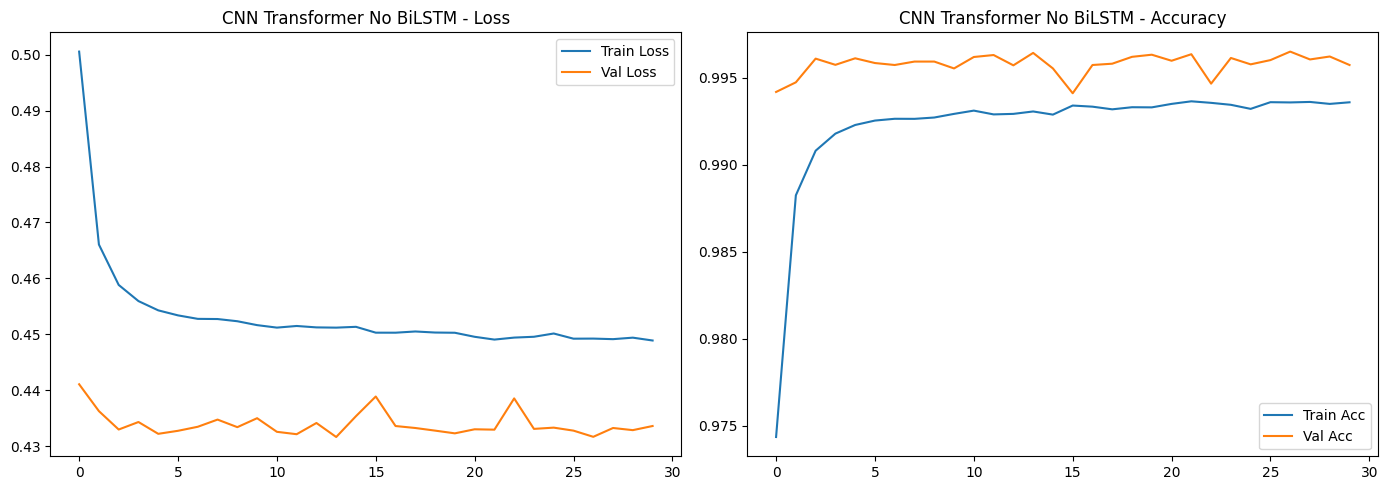

In [12]:
print("Training CNN+Transformer (No BiLSTM) Ablation Model...")
history_no_bilstm = train_model(model_no_bilstm, train_loader, val_loader, CONFIG['epochs'],
                                  save_path='cnn_transformer_no_bilstm_best.pth')
plot_history(history_no_bilstm, "CNN Transformer No BiLSTM")

In [13]:
print("Fitting MinMax Gate for CNN+Transformer (No BiLSTM)...")
train_feats_nb, train_labels_nb = get_prob_features(model_no_bilstm, train_loader, device, temperature=1.0)
gate_no_bilstm = MinMaxThreeWayGate(q=15).fit(train_feats_nb, train_labels_nb)
print(f"Gate fitted. Train feats shape: {train_feats_nb.shape}")

Fitting MinMax Gate for CNN+Transformer (No BiLSTM)...
Gate fitted. Train feats shape: (496866, 6)



  EVALUATION: CNN + Transformer (No BiLSTM)

  Total test samples  : 408735
  Predicted Emerging  : 303138 (excluded from metrics)
  Evaluated samples   : 105597

  Accuracy : 0.9958
  Precision: 0.9927
  Recall   : 0.9958
  F1-Score : 0.9941

  Classification Report (known classes only):
                        precision    recall  f1-score   support

                Benign       0.99      1.00      0.99     18885
DDoS_ACK_Fragmentation       1.00      1.00      1.00      4795
        DoS_HTTP_Flood       0.96      1.00      0.98      1093
         DoS_SYN_Flood       1.00      1.00      1.00     34248
         DoS_TCP_Flood       1.00      1.00      1.00     45729
         Mirai_udplain       0.00      0.00      0.00       388
     VulnerabilityScan       0.72      1.00      0.84       459

              accuracy                           1.00    105597
             macro avg       0.81      0.86      0.83    105597
          weighted avg       0.99      1.00      0.99    105597



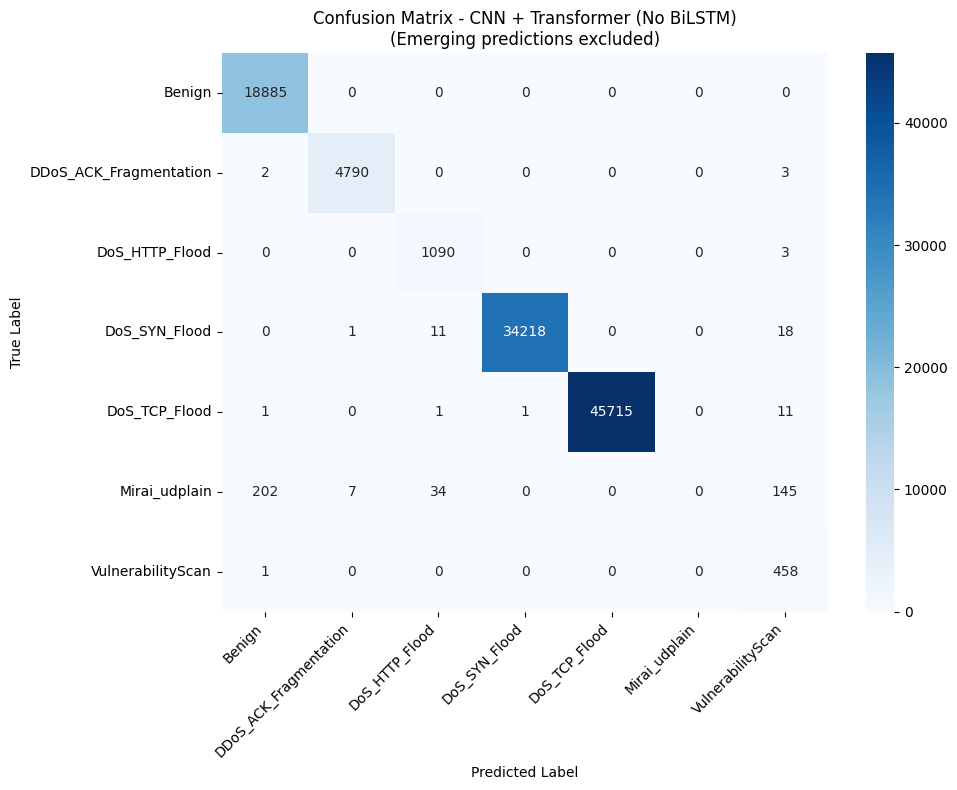

In [14]:
results_no_bilstm = evaluate_model(model_no_bilstm, test_loader, gate_no_bilstm, le,
                                     y_test_final_str, "CNN + Transformer (No BiLSTM)")